# FraudLens v3 — Cost-Sensitive Fraud Triage

**Decision improved:** which transactions should fraud analysts review first, when they can handle only **200 alerts per day**?

**What v3 adds on top of v2**
| Area | Change |
|---|---|
| Cost-sensitivity | Rank by **expected net benefit** (probability × amount at risk − review cost), not just by risk score. Compared head-to-head with the risk-ranked model at the **same 200-alert capacity**. |
| Metrics | PR-AUC, Precision@K, Recall@K, **false negatives, false positives, total cost, savings and % cost reduction**, with a paired bootstrap on the cost difference. |
| Explanations | **SHAP** indicators, plus an occlusion cross-check and a **stability test**. Described as *model-based indicators, not causes*. |
| Features | **Stream-level behavioural proxy features** (the public file has no customer ID) and a ready-to-use **per-customer feature function** for real data. Kept only if cross-validation says they help. |
| Labels | Neutral *amount units* — the dataset never states a currency. Lift is shown as a test-slice comparison, not a production promise. |

> **All cost numbers depend on the assumptions in the configuration cell.** They are illustrative until replaced with the client's real figures.

**Evaluation design**
* Model development: stratified random split (test keeps the real fraud ratio; never resampled).
* **Business evaluation: train on day 1, score day 2 with exactly 200 alerts** — the deployment-like setting.

---
### Running on Google Colab
Upload this notebook → **Runtime → Run all**. Data loads via Kaggle (`kagglehub`) or an upload prompt. Expect ~10–15 minutes on free Colab (tuning + calibration + SHAP). Set `RUN_TUNING=False` / `RUN_SHAP=False` to speed up.

## 1. Setup and configuration

In [2]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve, accuracy_score
from scipy.stats import randint, uniform, loguniform

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

def _ensure(pkg, import_name=None):
    import importlib, subprocess, sys
    try:
        return importlib.import_module(import_name or pkg)
    except ImportError:
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
            return importlib.import_module(import_name or pkg)
        except Exception as e:
            print(f"Could not install {pkg}: {repr(e)[:120]}")
            return None

lgb = _ensure("lightgbm")
shap = _ensure("shap")
assert lgb is not None, "LightGBM is required"

# ---- General configuration ------------------------------------------------
SEED = 42
ALERTS_PER_DAY = 200          # analyst capacity (from the brief) - identical for every policy we compare
TEST_SIZE = 0.25
N_BOOTSTRAP = 200
RUN_TUNING = True             # LightGBM random search (~5-8 min on free Colab)
TUNING_ITER = 12
RUN_SHAP = True               # SHAP explanations (needs the `shap` package)
CUSTOMER_COL = None           # set to a card/customer ID column name if your data has one (see section 4)
OUTPUT_DIR = "."

# ---- Business-cost assumptions (ILLUSTRATIVE - replace with the client's real numbers) ----
CURRENCY_LABEL = ""           # the Kaggle file does not state a currency; set e.g. "EUR" ONLY if you can establish it
LOSS_RATE = 1.0               # share of a fraudulent Amount that is lost if the fraud is NOT stopped
FIXED_FRAUD_COST = 0.0        # extra cost per missed fraud (chargeback fee, handling, ...), in amount units
ALERT_REVIEW_COST = 5.0       # analyst cost to review one alert, in amount units
FALSE_ALARM_FRICTION = 0.0    # extra customer-friction cost when a legitimate transaction is flagged

# ---- Data loading (Colab-friendly) ---------------------------------------
SEARCH_PATHS = ["creditcard.csv", "/content/creditcard.csv", "/content/drive/MyDrive/creditcard.csv"]
DATA_PATH = next((p for p in SEARCH_PATHS if os.path.exists(p)), None)

if DATA_PATH is None:
    try:
        kh = _ensure("kagglehub")
        folder = kh.dataset_download("mlg-ulb/creditcardfraud")
        DATA_PATH = os.path.join(folder, "creditcard.csv")
        print("Downloaded via kagglehub")
    except Exception as e:
        print("kagglehub download failed:", repr(e)[:200])
        DATA_PATH = None

if DATA_PATH is None or not os.path.exists(DATA_PATH):
    from google.colab import files
    print("Please select creditcard.csv (kaggle.com/datasets/mlg-ulb/creditcardfraud)")
    files.upload()
    DATA_PATH = "creditcard.csv"

assert os.path.exists(DATA_PATH), "creditcard.csv not found"
print("Using:", DATA_PATH)

UNIT = f" {CURRENCY_LABEL}" if CURRENCY_LABEL else " units"
def fmt_amt(x):
    return f"{x:,.2f}{UNIT}"

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Downloaded via kagglehub
Using: /kaggle/input/creditcardfraud/creditcard.csv


## 2. Load data and sanity checks

In [3]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print(f"Exact duplicate rows: {int(df.duplicated().sum())}")

fraud_rate = df["Class"].mean()
print(f"\nFraud: {int(df['Class'].sum())} of {len(df)}  ({fraud_rate:.3%})")
print(f"Time span: {df['Time'].max()/3600:.1f} hours = {df['Time'].max()/86400:.2f} days")
print(f"'Predict everything legitimate' accuracy: {1 - fraud_rate:.4%}  -> catches 0 fraud")

# Remove exact duplicates BEFORE splitting; sort by Time so 'history-only' features are well defined.
df = df.drop_duplicates().sort_values("Time", kind="stable").reset_index(drop=True)
print(f"After de-duplication: {df.shape}, fraud = {int(df['Class'].sum())} ({df['Class'].mean():.3%})")

Shape: (284807, 31)
Missing values: 0
Exact duplicate rows: 1081

Fraud: 492 of 284807  (0.173%)
Time span: 48.0 hours = 2.00 days
'Predict everything legitimate' accuracy: 99.8273%  -> catches 0 fraud
After de-duplication: (283726, 31), fraud = 473 (0.167%)


## 3. EDA

`Time` = seconds since the first transaction (not a clock time). `V1–V28` are anonymised PCA components — rankable, **not interpretable**.
The dataset never states the unit of `Amount`, so we call it *amount units*.

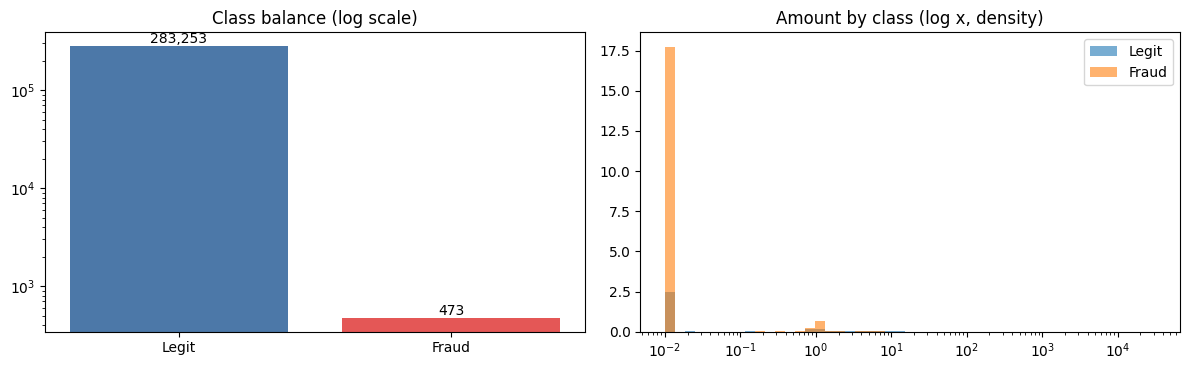

          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      283253.0   88.41  250.38  0.0  5.67  22.00   77.46  25691.16
1         473.0  123.87  260.21  0.0  1.00   9.82  105.89   2125.87


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
counts = df["Class"].value_counts().sort_index()
ax[0].bar(["Legit", "Fraud"], counts.values, color=["#4C78A8", "#E45756"])
ax[0].set_yscale("log"); ax[0].set_title("Class balance (log scale)")
for i, v in enumerate(counts.values):
    ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")
bins = np.logspace(-2, 4.5, 50)
ax[1].hist(df.loc[df.Class == 0, "Amount"].clip(lower=0.01), bins=bins, alpha=0.6, density=True, label="Legit")
ax[1].hist(df.loc[df.Class == 1, "Amount"].clip(lower=0.01), bins=bins, alpha=0.6, density=True, label="Fraud")
ax[1].set_xscale("log"); ax[1].set_title("Amount by class (log x, density)"); ax[1].legend()
plt.tight_layout(); plt.show()
print(df.groupby("Class")["Amount"].describe().round(2))

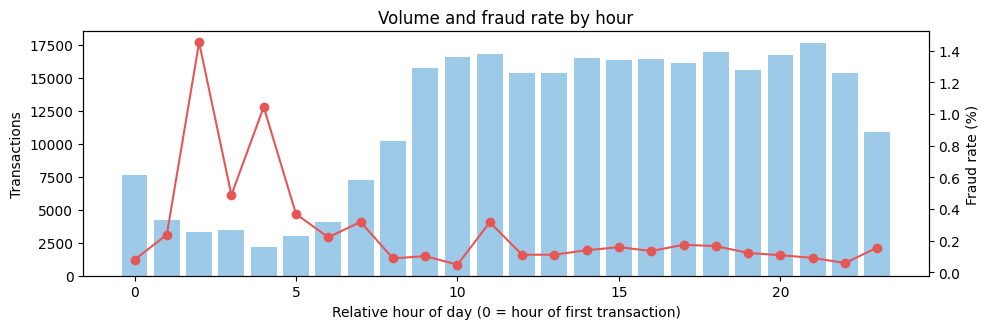

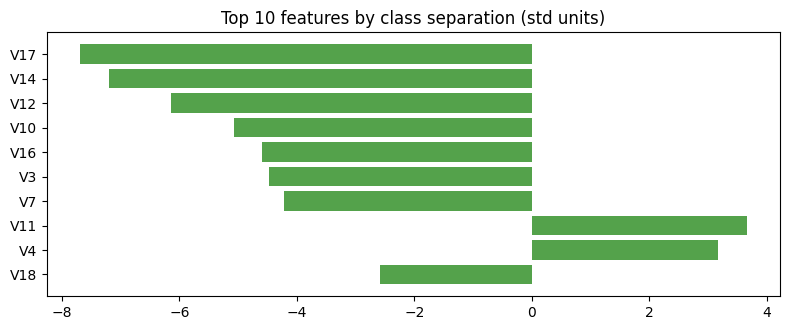

In [5]:
df["Hour"] = ((df["Time"] // 3600) % 24).astype(int)
by_hour = df.groupby("Hour")["Class"].agg(n="count", frauds="sum", fraud_rate="mean")
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(by_hour.index, by_hour["n"], color="#9ecae9")
ax.set_xlabel("Relative hour of day (0 = hour of first transaction)"); ax.set_ylabel("Transactions")
ax2 = ax.twinx(); ax2.plot(by_hour.index, by_hour["fraud_rate"] * 100, color="#E45756", marker="o")
ax2.set_ylabel("Fraud rate (%)"); ax.set_title("Volume and fraud rate by hour")
plt.tight_layout(); plt.show()

vcols = [f"V{i}" for i in range(1, 29)]
effect = ((df.loc[df.Class == 1, vcols].mean() - df.loc[df.Class == 0, vcols].mean()) / df[vcols].std())
top_effect = effect.reindex(effect.abs().sort_values(ascending=False).index).head(10)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(top_effect.index[::-1], top_effect.values[::-1], color="#54A24B")
ax.set_title("Top 10 features by class separation (std units)")
plt.tight_layout(); plt.show()

## 4. Behavioural features

**Honest scope:** the public file has **no card or customer identifier**, so *true per-customer behaviour* (a customer's usual spend, their recent transaction count, time since their last purchase) **cannot be computed here**.

What we do instead:
1. **`add_customer_features()`** — production-ready code for real data that has a customer/card ID. Set `CUSTOMER_COL` to use it. All features use *past* transactions only (no look-ahead).
2. **Stream-level proxy features** — computed from the transaction stream using only earlier rows: repeated identical amounts in the last hour (a card-testing / scripted-fraud pattern), time since the last identical amount, transaction volume in the last minute, and amount relative to recent typical amounts. **These are not per-customer behaviour** — they are context about the stream.

Neither set is assumed to help. Section 5 keeps them **only if cross-validation shows a gain**.

In [6]:
def add_base_features(d):
    d = d.copy()
    d["LogAmount"] = np.log1p(d["Amount"])
    hour = (d["Time"] // 3600) % 24
    d["Hour_sin"] = np.sin(2 * np.pi * hour / 24)
    d["Hour_cos"] = np.cos(2 * np.pi * hour / 24)
    return d

def add_stream_features(d):
    """History-only context features. Requires d sorted by Time. Uses no labels."""
    d = d.copy()
    n = len(d)
    t = d["Time"].values.astype(float)
    a = d["Amount"].values

    # volume in the previous 60 seconds (rows strictly earlier in the sorted stream)
    d["stream_tx_60s"] = np.arange(n) - np.searchsorted(t, t - 60, side="left")

    # repeated identical amounts: count in previous hour, and seconds since the last identical amount
    same_cnt = np.zeros(n)
    gap_same = np.full(n, 2 * 86400.0)
    for _, idx in d.groupby("Amount").indices.items():
        if len(idx) < 2:
            continue
        tt = t[idx]
        left = np.searchsorted(tt, tt - 3600, side="left")
        same_cnt[idx] = np.arange(len(idx)) - left
        gap = np.diff(tt, prepend=np.nan)
        gap_same[idx] = np.where(np.isnan(gap), 2 * 86400.0, gap)
    d["same_amt_1h"] = same_cnt
    d["log_secs_since_same_amt"] = np.log1p(gap_same)

    # amount relative to the median of the previous 100 amounts
    roll = d["Amount"].shift(1).rolling(100, min_periods=10).median()
    d["log_amt_vs_recent"] = np.log1p((d["Amount"] / (roll + 1e-3)).fillna(1.0))
    return d

STREAM_FEATURES = ["stream_tx_60s", "same_amt_1h", "log_secs_since_same_amt", "log_amt_vs_recent"]

def add_customer_features(d, customer_col):
    """Per-customer behavioural features for data WITH a customer/card ID. History-only (no look-ahead)."""
    d = d.sort_values("Time", kind="stable").reset_index(drop=True)
    n = len(d)
    t = d["Time"].values.astype(float)
    a = d["Amount"].values.astype(float)
    cols = {k: np.zeros(n) for k in ["cust_tx_1h", "cust_tx_24h", "cust_amt_z"]}
    cols["cust_log_gap"] = np.full(n, np.log1p(2 * 86400.0))
    for _, idx in d.groupby(customer_col).indices.items():
        tt, aa = t[idx], a[idx]
        pos = np.arange(len(idx))
        cols["cust_tx_1h"][idx] = pos - np.searchsorted(tt, tt - 3600, side="left")
        cols["cust_tx_24h"][idx] = pos - np.searchsorted(tt, tt - 86400, side="left")
        gap = np.diff(tt, prepend=np.nan)
        cols["cust_log_gap"][idx] = np.log1p(np.where(np.isnan(gap), 2 * 86400.0, gap))
        prev_n = pos
        mean = (np.cumsum(aa) - aa) / np.maximum(prev_n, 1)
        var = (np.cumsum(aa ** 2) - aa ** 2) / np.maximum(prev_n, 1) - mean ** 2
        sd = np.sqrt(np.maximum(var, 0))
        cols["cust_amt_z"][idx] = np.where(prev_n >= 3, (aa - mean) / (sd + 1.0), 0.0)
    for k, v in cols.items():
        d[k] = v
    return d

CUSTOMER_FEATURES = ["cust_tx_1h", "cust_tx_24h", "cust_log_gap", "cust_amt_z"]

df = add_base_features(df)
df = add_stream_features(df)
extra_features = list(STREAM_FEATURES)
if CUSTOMER_COL:
    assert CUSTOMER_COL in df.columns, f"{CUSTOMER_COL} not found in data"
    df = add_customer_features(df, CUSTOMER_COL)
    extra_features += CUSTOMER_FEATURES
    print("Per-customer features added:", CUSTOMER_FEATURES)
else:
    print("No customer ID in this dataset -> per-customer features skipped (function is ready for real data).")

print("\nStream-level proxy features, mean by class:")
print(df.groupby("Class")[STREAM_FEATURES].mean().round(3))

No customer ID in this dataset -> per-customer features skipped (function is ready for real data).

Stream-level proxy features, mean by class:
       stream_tx_60s  same_amt_1h  log_secs_since_same_amt  log_amt_vs_recent
Class                                                                        
0            124.822       39.513                    6.747              0.992
1            104.186       52.535                    6.755              1.038


## 5. Split (first!), capacity scaling, and feature selection by cross-validation

* Stratified train/test split; the test set keeps the **real** fraud ratio and is never resampled.
* The data covers ~2 days, so a 25% test slice is ~0.5 day → alert budget **K = 200 × test_days**. (The exact 200-per-day evaluation comes in section 10.)

In [7]:
BASE_FEATURES = [f"V{i}" for i in range(1, 29)] + ["LogAmount", "Hour_sin", "Hour_cos"]
FEATURES = list(BASE_FEATURES)

train, test = train_test_split(df, test_size=TEST_SIZE, stratify=df["Class"], random_state=SEED)
train = train.reset_index(drop=True); test = test.reset_index(drop=True)
y_tr, y_te = train["Class"].values, test["Class"].values

total_days = df["Time"].max() / 86400
test_days = total_days * TEST_SIZE
K = int(round(ALERTS_PER_DAY * test_days))

print(f"Train: {len(train):,} rows, {y_tr.sum()} frauds ({y_tr.mean():.3%})")
print(f"Test : {len(test):,} rows, {y_te.sum()} frauds ({y_te.mean():.3%})  <- real class ratio (never resampled)")
print(f"Test slice ~ {test_days:.2f} days of traffic -> alert budget K = {K}")

Train: 212,794 rows, 355 frauds (0.167%)
Test : 70,932 rows, 118 frauds (0.166%)  <- real class ratio (never resampled)
Test slice ~ 0.50 days of traffic -> alert budget K = 100


In [8]:
# ---------------- ranking wrappers: every model exposes .fit() and .score() ----------------
class Ranker:
    """Wraps a model and returns a standardised raw margin score (higher = riskier). Never saturates."""
    def __init__(self, est, kind):
        self.est, self.kind = est, kind
    def _raw(self, X):
        if self.kind == "lgbm":
            return self.est.predict(X, raw_score=True)
        return self.est.decision_function(X)
    def fit(self, X, y):
        self.est.fit(X, y)
        r = self._raw(X)
        self.mu, self.sd = r.mean(), r.std() + 1e-9
        return self
    def score(self, X):
        return (self._raw(X) - self.mu) / self.sd

class Blend:
    """Average of already-fitted Rankers."""
    def __init__(self, parts):
        self.parts = parts
    def score(self, X):
        return np.mean([p.score(X) for p in self.parts], axis=0)

def make_lr():
    return Ranker(make_pipeline(StandardScaler(),
                                LogisticRegression(class_weight="balanced", max_iter=2000, C=0.1)), "lr")

LGBM_DEFAULT = dict(n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=20,
                    subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=5.0,
                    scale_pos_weight=25, max_bin=63, random_state=SEED, n_jobs=-1, verbose=-1)

def make_lgbm(params):
    return Ranker(lgb.LGBMClassifier(**params), "lgbm")

def evaluate(y_true, scores, k, with_roc=True):
    y_true = np.asarray(y_true); scores = np.asarray(scores)
    top = np.argsort(-scores)[:k]
    tp = y_true[top].sum()
    out = {"PR_AUC": average_precision_score(y_true, scores),
           "Precision@K": tp / k,
           "Recall@K": tp / max(y_true.sum(), 1)}
    if with_roc:
        out["ROC_AUC"] = roc_auc_score(y_true, scores)
    return out

In [9]:
# Do the stream-level / customer features earn their place? 5-fold CV PR-AUC on the TRAINING set only.
def cv_pr_auc(features, n_splits=5):
    skf = StratifiedKFold(n_splits, shuffle=True, random_state=SEED + 1)
    out = []
    for tr, va in skf.split(train, y_tr):
        m = make_lgbm(LGBM_DEFAULT).fit(train.iloc[tr][features], y_tr[tr])
        out.append(average_precision_score(y_tr[va], m.score(train.iloc[va][features])))
    return np.array(out)

ap_base = cv_pr_auc(BASE_FEATURES)
ap_extra = cv_pr_auc(BASE_FEATURES + extra_features)
diff = ap_extra - ap_base
print(f"Base features          : CV PR-AUC {ap_base.mean():.3f} +/- {ap_base.std():.3f}")
print(f"Base + behavioural     : CV PR-AUC {ap_extra.mean():.3f} +/- {ap_extra.std():.3f}")
print(f"Per-fold difference    : {np.round(diff, 3)}  (better in {(diff > 0).sum()} of {len(diff)} folds)")

use_extra = (diff.mean() > 0.005) and ((diff > 0).sum() >= 4)
FEATURES = BASE_FEATURES + (extra_features if use_extra else [])
print(f"\n-> Using {'BASE + BEHAVIOURAL' if use_extra else 'BASE'} features ({len(FEATURES)} columns). "
      "Rule: keep extras only if the mean gain > 0.005 PR-AUC and they win in >= 4 of 5 folds.")

X_tr, X_te = train[FEATURES], test[FEATURES]

Base features          : CV PR-AUC 0.833 +/- 0.046
Base + behavioural     : CV PR-AUC 0.836 +/- 0.026
Per-fold difference    : [ 0.013 -0.038  0.008  0.003  0.031]  (better in 4 of 5 folds)

-> Using BASE features (31 columns). Rule: keep extras only if the mean gain > 0.005 PR-AUC and they win in >= 4 of 5 folds.


## 6. Metrics, including business cost

Cost model (per the configuration cell):
* a **missed fraud** costs `Amount × LOSS_RATE + FIXED_FRAUD_COST`
* every **reviewed alert** costs `ALERT_REVIEW_COST` (plus `FALSE_ALARM_FRICTION` if it was legitimate)
* an alert on a real fraud is assumed to **stop** that fraud

**Total cost** = missed-fraud losses + review costs. The **no-model** reference is: review nothing, lose every fraud.

In [10]:
def queue_cost(y, amount, idx, review=None, fixed=None, loss_rate=None, friction=None):
    review = ALERT_REVIEW_COST if review is None else review
    fixed = FIXED_FRAUD_COST if fixed is None else fixed
    loss_rate = LOSS_RATE if loss_rate is None else loss_rate
    friction = FALSE_ALARM_FRICTION if friction is None else friction
    in_q = np.zeros(len(y), dtype=bool); in_q[idx] = True
    missed = (y == 1) & ~in_q
    fp = int(((y == 0) & in_q).sum())
    loss = float(amount[missed].sum() * loss_rate + fixed * missed.sum())
    rev = float(in_q.sum() * review)
    fr = float(fp * friction)
    return dict(TP=int(((y == 1) & in_q).sum()), FP=fp, FN=int(missed.sum()),
                missed_loss=loss, review_cost=rev, friction=fr, total=loss + rev + fr)

def expected_benefit(p, amount, review=None, fixed=None, loss_rate=None, friction=None):
    """Expected net gain of reviewing a transaction with fraud probability p and given Amount."""
    review = ALERT_REVIEW_COST if review is None else review
    fixed = FIXED_FRAUD_COST if fixed is None else fixed
    loss_rate = LOSS_RATE if loss_rate is None else loss_rate
    friction = FALSE_ALARM_FRICTION if friction is None else friction
    return p * (amount * loss_rate + fixed) - review - (1 - p) * friction

def topk(score, k):
    idx = np.argpartition(-score, k - 1)[:k]
    return idx[np.argsort(-score[idx])]

def policy_table(y, amount, score_map, k):
    """One comparison table: no model, random queue, and each ranking policy - all with the SAME alert budget k."""
    n, n_fraud = len(y), int(y.sum())
    all_loss = float(amount[y == 1].sum() * LOSS_RATE + FIXED_FRAUD_COST * n_fraud)
    rows = [dict(Policy="No model (review nothing)", PR_AUC=np.nan, **{"Precision@K": np.nan, "Recall@K": 0.0},
                 TP=0, FP=0, FN=n_fraud, total=all_loss)]
    tp_r = k * n_fraud / n
    rows.append(dict(Policy="Random queue (expected)", PR_AUC=n_fraud / n, **{"Precision@K": n_fraud / n, "Recall@K": k / n},
                     TP=tp_r, FP=k - tp_r, FN=n_fraud - tp_r,
                     total=all_loss * (1 - k / n) + k * ALERT_REVIEW_COST + (k - tp_r) * FALSE_ALARM_FRICTION))
    for name, sc in score_map.items():
        c = queue_cost(y, amount, topk(sc, k))
        rows.append(dict(Policy=name, PR_AUC=average_precision_score(y, sc),
                         **{"Precision@K": c["TP"] / k, "Recall@K": c["TP"] / max(n_fraud, 1)},
                         TP=c["TP"], FP=c["FP"], FN=c["FN"], total=c["total"]))
    t = pd.DataFrame(rows).set_index("Policy")
    t["Savings vs no model"] = all_loss - t["total"]
    t["Cost reduction %"] = 100 * t["Savings vs no model"] / all_loss
    t = t.rename(columns={"total": "Total cost", "TP": "Frauds caught (TP)", "FP": "False alarms (FP)", "FN": "Missed frauds (FN)"})
    return t, all_loss

print(f"Cost assumptions (amount units): loss rate {LOSS_RATE:.0%} of fraud Amount, fixed cost per missed fraud {FIXED_FRAUD_COST}, "
      f"review cost per alert {ALERT_REVIEW_COST}, false-alarm friction {FALSE_ALARM_FRICTION}")
print(f"All-legit accuracy on test: {accuracy_score(y_te, np.zeros_like(y_te)):.4%} (fraud caught: 0)")
print(f"PR-AUC of a random ranking: {y_te.mean():.4f} (= fraud rate)")

Cost assumptions (amount units): loss rate 100% of fraud Amount, fixed cost per missed fraud 0.0, review cost per alert 5.0, false-alarm friction 0.0
All-legit accuracy on test: 99.8336% (fraud caught: 0)
PR-AUC of a random ranking: 0.0017 (= fraud rate)


## 7. Models — LightGBM, logistic baseline and ensemble (chosen by cross-validation)

All models rank by their **raw margin score**, not `predict_proba`, because probabilities saturate at 1.0 and create ties in the top of the queue.
No undersampling, no SMOTE: class weights live inside training only.

In [11]:
best_params = dict(LGBM_DEFAULT)
if RUN_TUNING:
    space = dict(n_estimators=randint(200, 500), learning_rate=loguniform(0.01, 0.1), num_leaves=randint(4, 40),
                 min_child_samples=randint(5, 60), subsample=uniform(0.6, 0.4), colsample_bytree=uniform(0.4, 0.6),
                 reg_lambda=loguniform(0.1, 50), scale_pos_weight=[1, 5, 25, 100, 300])
    search = RandomizedSearchCV(
        lgb.LGBMClassifier(subsample_freq=1, max_bin=63, random_state=SEED, n_jobs=-1, verbose=-1),
        space, n_iter=TUNING_ITER, scoring="average_precision",
        cv=StratifiedKFold(3, shuffle=True, random_state=SEED), random_state=SEED, n_jobs=1, verbose=1)
    search.fit(X_tr, y_tr)
    best_params = {**LGBM_DEFAULT, **search.best_params_}
    print(f"Best tuning PR-AUC (3-fold): {search.best_score_:.3f}")

LR_NAME, LGBM_DEF_NAME = "Logistic (balanced)", "LightGBM (baseline params)"
LGBM_TUNED_NAME, ENS_NAME = "LightGBM (tuned)", "Ensemble (LR + LightGBM tuned)"
models = [LR_NAME, LGBM_DEF_NAME, LGBM_TUNED_NAME, ENS_NAME]

def fit_candidate(name, X, y):
    if name == ENS_NAME:
        return Blend([fit_candidate(LR_NAME, X, y), fit_candidate(LGBM_TUNED_NAME, X, y)])
    if name == LR_NAME:
        return make_lr().fit(X, y)
    if name == LGBM_DEF_NAME:
        return make_lgbm(LGBM_DEFAULT).fit(X, y)
    return make_lgbm(best_params).fit(X, y)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
fold_ap = {n: [] for n in models}
for tr, va in skf.split(X_tr, y_tr):
    Xt, yt, Xv, yv = X_tr.iloc[tr], y_tr[tr], X_tr.iloc[va], y_tr[va]
    parts = {LR_NAME: make_lr().fit(Xt, yt),
             LGBM_DEF_NAME: make_lgbm(LGBM_DEFAULT).fit(Xt, yt),
             LGBM_TUNED_NAME: make_lgbm(best_params).fit(Xt, yt)}
    parts[ENS_NAME] = Blend([parts[LR_NAME], parts[LGBM_TUNED_NAME]])
    for n, m in parts.items():
        fold_ap[n].append(average_precision_score(yv, m.score(Xv)))

cv_df = pd.DataFrame({"CV PR-AUC mean": {n: np.mean(v) for n, v in fold_ap.items()},
                      "CV PR-AUC std": {n: np.std(v) for n, v in fold_ap.items()}})
display(cv_df.round(3))
best_name = cv_df["CV PR-AUC mean"].idxmax()
print(f"Selected by CV (not by the test set): {best_name}")
print("Note: tuned settings were chosen on the same training data, so their CV score is slightly optimistic; the held-out test is the honest check.")

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best tuning PR-AUC (3-fold): 0.846


,CV PR-AUC mean,CV PR-AUC std
Logistic (balanced),0.757,0.028
LightGBM (baseline params),0.833,0.046
LightGBM (tuned),0.850,0.037
Ensemble (LR + LightGBM tuned),0.802,0.026


Selected by CV (not by the test set): LightGBM (tuned)
Note: tuned settings were chosen on the same training data, so their CV score is slightly optimistic; the held-out test is the honest check.


,PR_AUC,Precision@100,Recall@100,ROC_AUC
Model,,,,
Logistic (balanced),0.683,0.87,0.737,0.968
LightGBM (baseline params),0.790,0.87,0.737,0.982
LightGBM (tuned),0.818,0.91,0.771,0.979
Ensemble (LR + LightGBM tuned),0.738,0.87,0.737,0.978


Recall@100 cannot exceed 85%: the queue holds 100 alerts but this test slice has 118 frauds.


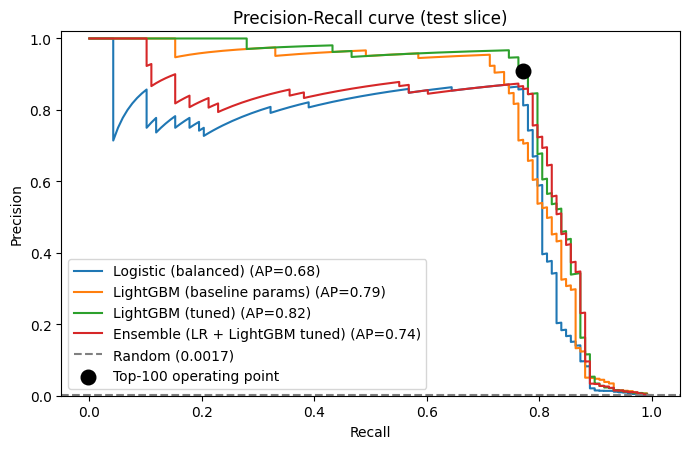

In [12]:
fitted, test_scores, rows = {}, {}, []
for name in models:
    fm = fit_candidate(name, X_tr, y_tr)
    fitted[name] = fm
    sc = fm.score(X_te)
    test_scores[name] = sc
    rows.append({"Model": name, **evaluate(y_te, sc, K)})

results = pd.DataFrame(rows).set_index("Model")
results = results.rename(columns={"Precision@K": f"Precision@{K}", "Recall@K": f"Recall@{K}"})
display(results.round(3))
ceiling = min(1.0, K / y_te.sum())
print(f"Recall@{K} cannot exceed {ceiling:.0%}: the queue holds {K} alerts but this test slice has {int(y_te.sum())} frauds.")

best_model = fitted[best_name]
scores = test_scores[best_name]

fig, ax = plt.subplots(figsize=(7, 4.6))
for name, sc in test_scores.items():
    p_, r_, _ = precision_recall_curve(y_te, sc)
    ax.plot(r_, p_, label=f"{name} (AP={average_precision_score(y_te, sc):.2f})")
ax.axhline(y_te.mean(), color="grey", ls="--", label=f"Random ({y_te.mean():.4f})")
ev = evaluate(y_te, scores, K, with_roc=False)
ax.scatter([ev["Recall@K"]], [ev["Precision@K"]], s=110, color="black", zorder=5, label=f"Top-{K} operating point")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title("Precision-Recall curve (test slice)")
ax.legend(loc="lower left"); ax.set_ylim(0, 1.02)
plt.tight_layout(); plt.show()

In [13]:
# Bootstrap uncertainty for the selected model (the test slice holds only ~100-120 frauds)
rng = np.random.default_rng(SEED)
boot, n_te = [], len(y_te)
for _ in range(N_BOOTSTRAP):
    idx = rng.integers(0, n_te, n_te)
    if y_te[idx].sum() == 0:
        continue
    boot.append(evaluate(y_te[idx], scores[idx], K, with_roc=False))
ci = pd.DataFrame(boot).quantile([0.05, 0.5, 0.95]).T
ci.columns = ["5%", "median", "95%"]
display(ci.round(3))

# Why we never undersample the test set (same model, same threshold)
thr = np.sort(scores)[::-1][K - 1]
prec_real = y_te[scores >= thr].mean()
sel = np.concatenate([np.where(y_te == 1)[0],
                      rng.choice(np.where(y_te == 0)[0], size=2000, replace=False)])
prec_us = y_te[sel][scores[sel] >= thr].mean()
print(f"Precision on the REAL test slice: {prec_real:.1%} | on an undersampled test set ({y_te[sel].mean():.1%} fraud): {prec_us:.1%}  <- misleading")

,5%,median,95%
PR_AUC,0.758,0.818,0.870
Precision@K,0.770,0.900,0.980
Recall@K,0.698,0.759,0.826


Precision on the REAL test slice: 91.0% | on an undersampled test set (5.6% fraud): 98.9%  <- misleading


## 8. Cost-sensitive policy: rank by expected net benefit

The risk-ranked model orders transactions by *how likely* they are to be fraud. A cost-aware policy orders them by *how much it is worth reviewing them*:

> expected benefit = P(fraud) × (Amount × loss rate + fixed cost) − review cost − P(legit) × friction

This needs **calibrated probabilities**, so we fit a Platt (sigmoid) calibrator on **out-of-fold** scores from the training data (never on test data). With only a few hundred frauds, a sigmoid is safer than isotonic.
The capacity stays the same: **both policies review exactly K alerts**.

In [14]:
def fit_calibrator(name, X, y, n_splits=5, seed=SEED + 2):
    """Platt calibration of the model's score using out-of-fold predictions."""
    oof = np.zeros(len(y))
    for tr, va in StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(X, y):
        m = fit_candidate(name, X.iloc[tr], y[tr])
        oof[va] = m.score(X.iloc[va])
    return LogisticRegression(C=1e6, max_iter=1000).fit(oof.reshape(-1, 1), y)

def calibrated(cal, s):
    return cal.predict_proba(np.asarray(s).reshape(-1, 1))[:, 1]

cal_A = fit_calibrator(best_name, X_tr, y_tr)
p_te = calibrated(cal_A, scores)
print(f"Calibration sanity check on the test slice: sum of predicted probabilities = {p_te.sum():.0f} vs actual frauds = {int(y_te.sum())}")

amt_te = test["Amount"].values
benefit_te = expected_benefit(p_te, amt_te)
table_A, _ = policy_table(y_te, amt_te, {"Risk-ranked (current)": scores,
                                         "Cost-sensitive (expected benefit)": benefit_te}, K)
print(f"\nTest slice, K = {K} alerts for every policy (costs in amount units for this slice):")
display(table_A.round(3))

Calibration sanity check on the test slice: sum of predicted probabilities = 111 vs actual frauds = 118

Test slice, K = 100 alerts for every policy (costs in amount units for this slice):


,PR_AUC,Precision@K,Recall@K,Frauds caught (TP),False alarms (FP),Missed frauds (FN),Total cost,Savings vs no model,Cost reduction %
Policy,,,,,,,,,
No model (review nothing),NaN,NaN,0.000,0.000,0.000,118.000,17497.650,0.000,0.000
Random queue (expected),0.002,0.002,0.001,0.166,99.834,117.834,17972.982,-475.332,-2.717
Risk-ranked (current),0.818,0.910,0.771,91.000,9.000,27.000,4565.210,12932.440,73.910
Cost-sensitive (expected benefit),0.417,0.510,0.432,51.000,49.000,67.000,3698.220,13799.430,78.864


## 9. Business evaluation: train on day 1, score day 2 with exactly 200 alerts

This is the deployment-like setting: the model only knows the past, and analysts review **exactly 200 alerts for the day**.

In [15]:
day1 = df[df["Time"] < 86400].reset_index(drop=True)
day2 = df[df["Time"] >= 86400].reset_index(drop=True)
y1, y2 = day1["Class"].values, day2["Class"].values
amt2 = day2["Amount"].values
K2 = ALERTS_PER_DAY
print(f"Day 1: {len(day1):,} rows, {int(y1.sum())} frauds | Day 2: {len(day2):,} rows, {int(y2.sum())} frauds | alert budget = {K2}")

model_B = fit_candidate(best_name, day1[FEATURES], y1)
cal_B = fit_calibrator(best_name, day1[FEATURES], y1)
s2 = model_B.score(day2[FEATURES])
p2 = calibrated(cal_B, s2)
benefit2 = expected_benefit(p2, amt2)
print(f"Calibration check on day 2: sum of probabilities = {p2.sum():.0f} vs actual frauds = {int(y2.sum())}")

table_B, all_loss_B = policy_table(y2, amt2, {"Risk-ranked (current)": s2,
                                              "Cost-sensitive (expected benefit)": benefit2}, K2)
print(f"\nDay 2, exactly {K2} alerts for every policy (costs in amount units):")
display(table_B.round(3))

n_pos = int((benefit2 > 0).sum())
print(f"\nTransactions with positive expected benefit under these cost assumptions: {n_pos:,}")
print(f"Expected benefit of the marginal (200th) alert: {np.sort(benefit2)[::-1][K2 - 1]:.2f}")
if n_pos > K2:
    print("-> More transactions are worth reviewing than analysts can handle: capacity is the binding constraint.")
else:
    print("-> Fewer than 200 transactions are worth reviewing under these costs; analysts need not use their full capacity.")

Day 1: 144,236 rows, 272 frauds | Day 2: 139,490 rows, 201 frauds | alert budget = 200
Calibration check on day 2: sum of probabilities = 235 vs actual frauds = 201

Day 2, exactly 200 alerts for every policy (costs in amount units):


,PR_AUC,Precision@K,Recall@K,Frauds caught (TP),False alarms (FP),Missed frauds (FN),Total cost,Savings vs no model,Cost reduction %
Policy,,,,,,,,,
No model (review nothing),NaN,NaN,0.000,0.000,0.000,201.000,26122.450,0.000,0.000
Random queue (expected),0.001,0.001,0.001,0.288,199.712,200.712,27084.996,-962.546,-3.685
Risk-ranked (current),0.784,0.780,0.776,156.000,44.000,45.000,10654.510,15467.940,59.213
Cost-sensitive (expected benefit),0.333,0.385,0.383,77.000,123.000,124.000,10109.770,16012.680,61.299



Transactions with positive expected benefit under these cost assumptions: 328
Expected benefit of the marginal (200th) alert: 4.85
-> More transactions are worth reviewing than analysts can handle: capacity is the binding constraint.


In [16]:
# Is the cost difference real or noise? Paired bootstrap over day-2 transactions (same K for both policies).
rng = np.random.default_rng(SEED)
c_risk, c_cost = [], []
n2 = len(y2)
for _ in range(N_BOOTSTRAP):
    idx = rng.integers(0, n2, n2)
    yb, ab = y2[idx], amt2[idx]
    c_risk.append(queue_cost(yb, ab, topk(s2[idx], K2))["total"])
    c_cost.append(queue_cost(yb, ab, topk(benefit2[idx], K2))["total"])
c_risk, c_cost = np.array(c_risk), np.array(c_cost)
saving = c_risk - c_cost
win_rate = (saving > 0).mean()
lo, hi = np.percentile(saving, [5, 95])
print(f"Cost-sensitive vs risk-ranked: mean extra saving {saving.mean():,.0f} units (90% interval {lo:,.0f} to {hi:,.0f}); "
      f"cost-sensitive cheaper in {win_rate:.0%} of bootstrap resamples.")

# Sensitivity: do the conclusions survive different cost assumptions?
sens = []
for review in [1, 5, 20, 50]:
    for fixed in [0, 100]:
        b = expected_benefit(p2, amt2, review=review, fixed=fixed)
        risk_cost = queue_cost(y2, amt2, topk(s2, K2), review=review, fixed=fixed)["total"]
        cs_cost = queue_cost(y2, amt2, topk(b, K2), review=review, fixed=fixed)["total"]
        sens.append(dict(review_cost=review, fixed_cost_per_missed_fraud=fixed,
                         risk_ranked_total=risk_cost, cost_sensitive_total=cs_cost, extra_saving=risk_cost - cs_cost))
display(pd.DataFrame(sens).round(0))

# Decision rule: adopt the cost-sensitive policy only if it is cheaper, robustly, and does not wreck precision/recall.
t_r, t_c = table_B.loc["Risk-ranked (current)"], table_B.loc["Cost-sensitive (expected benefit)"]
cheaper = t_c["Total cost"] < t_r["Total cost"]
robust = win_rate >= 0.80
not_wrecked = (t_c["Recall@K"] >= t_r["Recall@K"] - 0.10) and (t_c["Precision@K"] >= t_r["Precision@K"] - 0.10)
POLICY = "cost-sensitive" if (cheaper and robust and not_wrecked) else "risk-ranked"
print(f"\nDecision -> cheaper: {cheaper} | wins in >= 80% of resamples: {robust} | precision/recall within 10 pts: {not_wrecked}")
print(f"Selected policy: {POLICY.upper()}")
if POLICY == "risk-ranked":
    print("The cost-sensitive policy did not show a clear, robust advantage under these assumptions, so we keep the simpler risk-ranked policy.")

Cost-sensitive vs risk-ranked: mean extra saving 985 units (90% interval -180 to 2,623); cost-sensitive cheaper in 84% of bootstrap resamples.


,review_cost,fixed_cost_per_missed_fraud,risk_ranked_total,cost_sensitive_total,extra_saving
0,1,0,9855.0,9310.0,545.0
1,1,100,14355.0,14008.0,346.0
2,5,0,10655.0,10110.0,545.0
3,5,100,15155.0,14808.0,346.0
4,20,0,13655.0,13110.0,545.0
5,20,100,18155.0,17808.0,346.0
6,50,0,19655.0,19110.0,545.0
7,50,100,24155.0,23808.0,346.0



Decision -> cheaper: True | wins in >= 80% of resamples: True | precision/recall within 10 pts: False
Selected policy: RISK-RANKED
The cost-sensitive policy did not show a clear, robust advantage under these assumptions, so we keep the simpler risk-ranked policy.


## 10. Explanations: SHAP indicators (model-based, not causes)

**How to read these.** The listed features are the ones that most push the model's risk score *up* for that transaction. They are **model-based indicators, not proven causes of fraud**.
`V1–V28` are anonymised PCA components, and correlated components can share or swap credit, so we also test how **stable** the indicators are.

Checks performed:
1. **SHAP** (permutation explainer on the actual scoring function, 100 legitimate background rows).
2. **Occlusion cross-check** (replace a feature with the legitimate median; see how much the score drops).
3. **Stability:** refit the model on a bootstrap resample of the training data and compare each alert's top-3 indicators (Jaccard overlap: 1.0 = identical).

In [17]:
legit_reference = day1.loc[y1 == 0, FEATURES].median()
background = day1.loc[y1 == 0, FEATURES].sample(100, random_state=SEED)

# queue for the selected policy
rank_score = benefit2 if POLICY == "cost-sensitive" else s2
top_idx = topk(rank_score, K2)
alerts = day2.iloc[top_idx].copy().reset_index(drop=True)
X_alert = alerts[FEATURES]

def occlusion_indicators(model, X_alert, reference, top_n=3):
    base = model.score(X_alert)
    drops = np.zeros((len(X_alert), len(FEATURES)))
    for j, f in enumerate(FEATURES):
        Xp = X_alert.copy(); Xp[f] = reference[f]
        drops[:, j] = base - model.score(Xp)
    return [[(FEATURES[j], X_alert.iloc[i][FEATURES[j]], drops[i, j]) for j in np.argsort(-drops[i])[:top_n]]
            for i in range(len(X_alert))]

def shap_indicators(model, X_alert, background, top_n=3, max_evals=250):
    f = lambda a: model.score(pd.DataFrame(a, columns=FEATURES))
    masker = shap.maskers.Independent(background.values, max_samples=100)
    expl = shap.Explainer(f, masker, algorithm="permutation")
    sv = expl(X_alert.values, max_evals=max_evals, silent=True).values
    return [[(FEATURES[j], X_alert.iloc[i][FEATURES[j]], sv[i, j]) for j in np.argsort(-sv[i])[:top_n]]
            for i in range(len(X_alert))]

def jaccard(a, b):
    sa, sb = {x[0] for x in a}, {x[0] for x in b}
    return len(sa & sb) / len(sa | sb)

occ = occlusion_indicators(model_B, X_alert, legit_reference)
use_shap = bool(RUN_SHAP and shap is not None)
if use_shap:
    try:
        shp = shap_indicators(model_B, X_alert, background)
        INDICATOR_METHOD = "SHAP"
    except Exception as e:
        print("SHAP failed, falling back to occlusion:", repr(e)[:200])
        use_shap = False
if not use_shap:
    shp, INDICATOR_METHOD = occ, "occlusion"
indicators = shp
print(f"Indicator method used in the alert queue: {INDICATOR_METHOD}")

if use_shap:
    agree = np.mean([jaccard(a, b) for a, b in zip(shp, occ)])
    print(f"SHAP vs occlusion top-3 overlap (mean Jaccard): {agree:.2f}")

# Stability: refit on a bootstrap resample of day 1 and compare indicators for the same alerts
rng = np.random.default_rng(SEED)
bidx = rng.integers(0, len(day1), len(day1))
model_boot = fit_candidate(best_name, day1[FEATURES].iloc[bidx], y1[bidx])
alt = shap_indicators(model_boot, X_alert, background) if use_shap else occlusion_indicators(model_boot, X_alert, legit_reference)
stab = np.array([jaccard(a, b) for a, b in zip(indicators, alt)])
print(f"Stability across a bootstrap refit: mean Jaccard {stab.mean():.2f}; "
      f"{(stab >= 0.5).mean():.0%} of alerts keep at least 2 of their top-3 indicators")
print("Low stability means: treat the exact indicator list cautiously (correlated PCA components can trade places).")

Indicator method used in the alert queue: SHAP
SHAP vs occlusion top-3 overlap (mean Jaccard): 0.83
Stability across a bootstrap refit: mean Jaccard 0.83; 100% of alerts keep at least 2 of their top-3 indicators
Low stability means: treat the exact indicator list cautiously (correlated PCA components can trade places).


## 11. The deliverable — the 200-alert daily queue

Every action is **`PENDING_APPROVAL`**: an analyst decides; nothing is blocked automatically. Indicators are model-based, not causes.

In [18]:
alerts["Rank"] = np.arange(1, K2 + 1)
alerts["Risk_score"] = s2[top_idx]
alerts["Fraud_probability"] = p2[top_idx]
alerts["Expected_loss_avoided"] = alerts["Fraud_probability"] * (alerts["Amount"] * LOSS_RATE + FIXED_FRAUD_COST)
alerts["Expected_net_benefit"] = benefit2[top_idx]
alerts["Hour (relative)"] = ((alerts["Time"] // 3600) % 24).astype(int)
alerts["Model_indicators"] = [", ".join(f"{f}={v:+.1f}" for f, v, _ in r) for r in indicators]

def tier(rank, k):
    if rank <= max(1, int(np.ceil(0.10 * k))):
        return "HOLD & CALL CUSTOMER"
    if rank <= int(np.ceil(0.50 * k)):
        return "PRIORITY REVIEW (same day)"
    return "STANDARD REVIEW"

alerts["Action"] = [tier(r, K2) for r in alerts["Rank"]]
alerts["Analyst_Note"] = [
    f"#{r.Rank} | P(fraud) {r.Fraud_probability:.0%} | amount {fmt_amt(r.Amount)} at hour {int(r['Hour (relative)']):02d} "
    f"| model indicators: {r.Model_indicators} | action: {r.Action}"
    for _, r in alerts.iterrows()]
alerts["Status"] = "PENDING_APPROVAL"
alerts["Actual_Class (evaluation only)"] = alerts["Class"]

cols = ["Rank", "Risk_score", "Fraud_probability", "Amount", "Expected_loss_avoided", "Expected_net_benefit",
        "Hour (relative)", "Model_indicators", "Action", "Analyst_Note", "Status", "Actual_Class (evaluation only)"]
queue = alerts[cols]
out_path = os.path.join(OUTPUT_DIR, "alert_queue.csv")
queue.to_csv(out_path, index=False)
print(f"Saved {len(queue)} alerts ({POLICY} policy, indicators via {INDICATOR_METHOD}) -> {out_path}\n")
display(queue.head(10))
print("\nExample analyst note:\n", queue.loc[0, "Analyst_Note"])

Saved 200 alerts (risk-ranked policy, indicators via SHAP) -> ./alert_queue.csv



,Rank,Risk_score,Fraud_probability,Amount,Expected_loss_avoided,Expected_net_benefit,Hour (relative),Model_indicators,Action,Analyst_Note,Status,Actual_Class (evaluation only)
0,1,10.925325,0.992491,667.55,662.537055,657.537055,16,"V14=-7.5, V12=-4.9, V10=-6.5",HOLD & CALL CUSTOMER,#1 | P(fraud) 99% | amount 667.55 units at hou...,PENDING_APPROVAL,1
1,2,10.812886,0.991327,104.03,103.127710,98.127710,2,"V14=-13.2, V12=-15.6, V10=-15.6",HOLD & CALL CUSTOMER,#2 | P(fraud) 99% | amount 104.03 units at hou...,PENDING_APPROVAL,1
2,3,10.722419,0.990262,188.52,186.684148,181.684148,2,"V14=-14.2, V12=-16.5, V10=-14.9",HOLD & CALL CUSTOMER,#3 | P(fraud) 99% | amount 188.52 units at hou...,PENDING_APPROVAL,1
3,4,10.699181,0.989968,316.06,312.889269,307.889269,2,"V14=-14.1, V12=-17.0, V10=-13.3",HOLD & CALL CUSTOMER,#4 | P(fraud) 99% | amount 316.06 units at hou...,PENDING_APPROVAL,1
4,5,10.656531,0.989406,1.00,0.989406,-4.010594,18,"V14=-13.7, V12=-8.8, V4=+7.8",HOLD & CALL CUSTOMER,#5 | P(fraud) 99% | amount 1.00 units at hour ...,PENDING_APPROVAL,1
5,6,10.644748,0.989245,1.00,0.989245,-4.010755,18,"V14=-14.0, V12=-9.0, V4=+7.8",HOLD & CALL CUSTOMER,#6 | P(fraud) 99% | amount 1.00 units at hour ...,PENDING_APPROVAL,1
6,7,10.644258,0.989238,1.00,0.989238,-4.010762,15,"V14=-8.9, V12=-5.7, V4=+7.2",HOLD & CALL CUSTOMER,#7 | P(fraud) 99% | amount 1.00 units at hour ...,PENDING_APPROVAL,1
7,8,10.641180,0.989196,130.21,128.803177,123.803177,13,"V14=-4.7, V12=-2.6, V10=-2.6",HOLD & CALL CUSTOMER,#8 | P(fraud) 99% | amount 130.21 units at hou...,PENDING_APPROVAL,1
8,9,10.636378,0.989129,156.00,154.304161,149.304161,20,"V14=-5.9, V12=-3.1, V10=-2.2",HOLD & CALL CUSTOMER,#9 | P(fraud) 99% | amount 156.00 units at hou...,PENDING_APPROVAL,1
9,10,10.632282,0.989072,45.51,45.012675,40.012675,10,"V14=-5.9, V12=-6.4, V10=-4.9",HOLD & CALL CUSTOMER,#10 | P(fraud) 99% | amount 45.51 units at hou...,PENDING_APPROVAL,1



Example analyst note:
 #1 | P(fraud) 99% | amount 667.55 units at hour 16 | model indicators: V14=-7.5, V12=-4.9, V10=-6.5 | action: HOLD & CALL CUSTOMER


## 12. Business summary for the pitch

In [19]:
chosen_name = "Cost-sensitive (expected benefit)" if POLICY == "cost-sensitive" else "Risk-ranked (current)"
row = table_B.loc[chosen_name]
tp = int(row["Frauds caught (TP)"]); fp = int(row["False alarms (FP)"]); fn = int(row["Missed frauds (FN)"])
precision_k, recall_k = row["Precision@K"], row["Recall@K"]
base_rate = y2.mean()
lift = precision_k / base_rate
saving_total = row["Savings vs no model"]

print("=" * 78)
print(f"DAY-2 SIMULATION | policy: {POLICY} | alert capacity: {K2} per day | costs in{UNIT} under the stated assumptions")
print("-" * 78)
print(f"Ranking quality (PR-AUC): {row['PR_AUC']:.3f}   (random ranking = {base_rate:.4f})")
print(f"Of {K2} alerts, {tp} were real fraud (precision {precision_k:.0%}); {fp} were false alarms.")
print(f"We caught {recall_k:.0%} of the day's {int(y2.sum())} frauds; {fn} were missed.")
print(f"Cost with no model     : {all_loss_B:,.0f}")
print(f"Cost with this policy  : {row['Total cost']:,.0f}   (missed-fraud losses + review costs)")
print(f"Savings                : {saving_total:,.0f}  ({row['Cost reduction %']:.0f}% reduction)")
print("-" * 78)
print(f"Context for the lift: on this day the fraud base rate was {base_rate:.3%}, so a queue at {precision_k:.0%} precision is "
      f"~{lift:,.0f}x richer than reviewing random transactions.")
print("This is a single-day, held-out comparison on a public dataset. A production result depends on the real base rate,")
print("fraud drift, true costs and analyst behaviour - it is not a guaranteed outcome.")
print("=" * 78)

DAY-2 SIMULATION | policy: risk-ranked | alert capacity: 200 per day | costs in units under the stated assumptions
------------------------------------------------------------------------------
Ranking quality (PR-AUC): 0.784   (random ranking = 0.0014)
Of 200 alerts, 156 were real fraud (precision 78%); 44 were false alarms.
We caught 78% of the day's 201 frauds; 45 were missed.
Cost with no model     : 26,122
Cost with this policy  : 10,655   (missed-fraud losses + review costs)
Savings                : 15,468  (59% reduction)
------------------------------------------------------------------------------
Context for the lift: on this day the fraud base rate was 0.144%, so a queue at 78% precision is ~541x richer than reviewing random transactions.
This is a single-day, held-out comparison on a public dataset. A production result depends on the real base rate,
fraud drift, true costs and analyst behaviour - it is not a guaranteed outcome.


## 13. (Bonus) MLflow run comparison

In [25]:

%pip install -q mlflow

In [26]:
import mlflow

mlflow.set_experiment("FraudLens")

# Log model comparison runs
for name in models:
    with mlflow.start_run(run_name=f"model: {name}"):
        mlflow.log_param("model", name)
        mlflow.log_param("K", int(K))

        mlflow.log_metric(
            "cv_pr_auc_mean",
            float(cv_df.loc[name, "CV PR-AUC mean"])
        )

        for metric, val in results.loc[name].items():
            try:
                if isinstance(val, (int, float)) and not isinstance(val, bool):
                    mlflow.log_metric(
                        str(metric).replace("@", "_at_").replace("-", "_"),
                        float(val)
                    )
            except (ValueError, TypeError):
                pass

# Log day-2 policy comparison runs
for pol in [
    "Risk-ranked (current)",
    "Cost-sensitive (expected benefit)"
]:
    with mlflow.start_run(run_name=f"policy day2: {pol}"):
        r = table_B.loc[pol]

        mlflow.log_param("policy", pol)
        mlflow.log_param("alerts", int(K2))

        for key, value in r.items():
            try:
                if isinstance(value, (int, float)) and not isinstance(value, bool):
                    metric_name = (
                        str(key)
                        .replace("@", "_at_")
                        .replace(" ", "_")
                        .replace("%", "pct")
                        .replace("(", "")
                        .replace(")", "")
                    )
                    mlflow.log_metric(metric_name, float(value))
            except (ValueError, TypeError):
                pass

print("Successfully logged FraudLens experiments!")
print("Experiment:", mlflow.get_experiment_by_name("FraudLens").name)
print("Total runs logged:", len(mlflow.search_runs(
    experiment_names=["FraudLens"]
)))

Successfully logged FraudLens experiments!
Experiment: FraudLens
Total runs logged: 12


In [27]:
display(
    mlflow.search_runs(
        experiment_names=["FraudLens"],
        order_by=["start_time DESC"]
    )
)

,run_id,experiment_id,status,artifact_uri,start_time,end_time,metrics.Missed_frauds_FN,metrics.False_alarms_FP,metrics.Total_cost,metrics.Precision_at_K,metrics.PR_AUC,metrics.Recall_at_K,metrics.Frauds_caught_TP,metrics.Savings_vs_no_model,metrics.Cost_reduction_pct,metrics.ROC_AUC,metrics.Precision_at_100,metrics.cv_pr_auc_mean,metrics.Recall_at_100,params.policy,params.alerts,params.model,params.K,tags.mlflow.source.name,tags.mlflow.runName,tags.mlflow.user,tags.mlflow.source.type
0,a7e277f3382c4ac688b70ee864ca3f28,1,FINISHED,/content/mlruns/1/a7e277f3382c4ac688b70ee864ca...,2026-10-10 09:34:45.418000+00:00,2026-10-10 09:34:45.605000+00:00,124.0,123.0,10109.77,0.385,0.333496,0.383085,77.0,16012.68,61.298538,NaN,NaN,NaN,NaN,Cost-sensitive (expected benefit),200,None,None,fileId=1tmde-UFmBhXnKMlknwKOuFVhF7ePX1gx,policy day2: Cost-sensitive (expected benefit),root,NOTEBOOK
1,cd3ef358597c41b1b5c35aa6868845b6,1,FINISHED,/content/mlruns/1/cd3ef358597c41b1b5c35aa68688...,2026-10-10 09:34:45.017000+00:00,2026-10-10 09:34:45.393000+00:00,45.0,44.0,10654.51,0.780,0.784207,0.776119,156.0,15467.94,59.213205,NaN,NaN,NaN,NaN,Risk-ranked (current),200,None,None,fileId=1tmde-UFmBhXnKMlknwKOuFVhF7ePX1gx,policy day2: Risk-ranked (current),root,NOTEBOOK
2,ccb9c0e27eec40b483d3f13af23d4531,1,FINISHED,/content/mlruns/1/ccb9c0e27eec40b483d3f13af23d...,2026-10-10 09:34:44.745000+00:00,2026-10-10 09:34:44.970000+00:00,NaN,NaN,NaN,NaN,0.738322,NaN,NaN,NaN,NaN,0.978398,0.87,0.801607,0.737288,None,None,Ensemble (LR + LightGBM tuned),100,fileId=1tmde-UFmBhXnKMlknwKOuFVhF7ePX1gx,model: Ensemble (LR + LightGBM tuned),root,NOTEBOOK
3,b3d48937208e443ca2b6c5cf3a2212ca,1,FINISHED,/content/mlruns/1/b3d48937208e443ca2b6c5cf3a22...,2026-10-10 09:34:44.627000+00:00,2026-10-10 09:34:44.730000+00:00,NaN,NaN,NaN,NaN,0.817863,NaN,NaN,NaN,NaN,0.979319,0.91,0.849738,0.771186,None,None,LightGBM (tuned),100,fileId=1tmde-UFmBhXnKMlknwKOuFVhF7ePX1gx,model: LightGBM (tuned),root,NOTEBOOK
4,a602d85b202241c892505d23cccc7055,1,FINISHED,/content/mlruns/1/a602d85b202241c892505d23cccc...,2026-10-10 09:34:44.516000+00:00,2026-10-10 09:34:44.613000+00:00,NaN,NaN,NaN,NaN,0.790153,NaN,NaN,NaN,NaN,0.981693,0.87,0.832664,0.737288,None,None,LightGBM (baseline params),100,fileId=1tmde-UFmBhXnKMlknwKOuFVhF7ePX1gx,model: LightGBM (baseline params),root,NOTEBOOK
5,7c4651072a8548258ff3ca0221ae44bb,1,FINISHED,/content/mlruns/1/7c4651072a8548258ff3ca0221ae...,2026-10-10 09:34:44.402000+00:00,2026-10-10 09:34:44.503000+00:00,NaN,NaN,NaN,NaN,0.682552,NaN,NaN,NaN,NaN,0.968213,0.87,0.756622,0.737288,None,None,Logistic (balanced),100,fileId=1tmde-UFmBhXnKMlknwKOuFVhF7ePX1gx,model: Logistic (balanced),root,NOTEBOOK
6,35c77da56941409294a10cb300542647,1,FINISHED,/content/mlruns/1/35c77da56941409294a10cb30054...,2026-10-10 09:16:57.816000+00:00,2026-10-10 09:16:57.953000+00:00,124.0,123.0,10109.77,0.385,0.333496,0.383085,77.0,16012.68,61.298538,NaN,NaN,NaN,NaN,Cost-sensitive (expected benefit),200,None,None,fileId=1tmde-UFmBhXnKMlknwKOuFVhF7ePX1gx,policy day2: Cost-sensitive (expected benefit),root,NOTEBOOK
7,dd14fd014a8e4cd182614e73624e8e88,1,FINISHED,/content/mlruns/1/dd14fd014a8e4cd182614e73624e...,2026-10-10 09:16:57.654000+00:00,2026-10-10 09:16:57.802000+00:00,45.0,44.0,10654.51,0.780,0.784207,0.776119,156.0,15467.94,59.213205,NaN,NaN,NaN,NaN,Risk-ranked (current),200,None,None,fileId=1tmde-UFmBhXnKMlknwKOuFVhF7ePX1gx,policy day2: Risk-ranked (current),root,NOTEBOOK
8,02b8312c275643719a5554cf5e025972,1,FINISHED,/content/mlruns/1/02b8312c275643719a5554cf5e02...,2026-10-10 09:16:57.546000+00:00,2026-10-10 09:16:57.641000+00:00,NaN,NaN,NaN,NaN,0.738322,NaN,NaN,NaN,NaN,0.978398,0.87,0.801607,0.737288,None,None,Ensemble (LR + LightGBM tuned),100,fileId=1tmde-UFmBhXnKMlknwKOuFVhF7ePX1gx,model: Ensemble (LR + LightGBM tuned),root,NOTEBOOK
9,a1a6a9399a5c4faa94f801b5dbea66bc,1,FINISHED,/content/mlruns/1/a1a6a9399a5c4faa94f801b5dbea...,2026-10-10 09:16:57.432000+00:00,2026-10-10 09:16:57.534000+00:00,NaN,

In [24]:

# try:
#     import mlflow
#     mlflow.set_experiment("FraudLens")
#     for name in models:
#         with mlflow.start_run(run_name=f"model: {name}"):
#             mlflow.log_param("model", name); mlflow.log_param("K", K)
#             mlflow.log_metric("cv_pr_auc_mean", float(cv_df.loc[name, "CV PR-AUC mean"]))
#             for metric, val in results.loc[name].items():
#                 mlflow.log_metric(metric.replace("@", "_at_").replace("-", "_"), float(val))
#     for pol in ["Risk-ranked (current)", "Cost-sensitive (expected benefit)"]:
#         with mlflow.start_run(run_name=f"policy day2: {pol}"):
#             r = table_B.loc[pol]
#             mlflow.log_param("policy", pol); mlflow.log_param("alerts", K2)
#             for k_, v_ in r.items():
#                 mlflow.log_metric(str(k_).replace("@", "_at_").replace(" ", "_").replace("%", "pct").replace("(", "").replace(")", ""), float(v_))
#     print("Logged. Compare runs with:  mlflow ui")
# except ImportError:
#     print("mlflow not installed - `pip install mlflow` (bonus points) or skip this cell.")

2026/10/10 09:16:53 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/10 09:16:53 INFO mlflow.store.db.utils: Updating database tables
2026/10/10 09:16:56 INFO mlflow.tracking.fluent: Experiment with name 'FraudLens' does not exist. Creating a new experiment.


Logged. Compare runs with:  mlflow ui


## 14. Pitch notes and honest limitations

**3-minute story:** 200 reviews/day → the accuracy lie (99.8%) → PR-AUC and Precision/Recall@200 → *cost*: what analysts' time and missed fraud really cost → live alert with its model indicators → savings under stated assumptions.

**Likely questions**
* *Why isn't accuracy used?* An all-legit model scores ~99.8% and catches nothing.
* *Where did you resample?* Nowhere. Class weights sit inside training; the test data keeps the real ratio.
* *How were the cost numbers chosen?* They are **explicit, illustrative assumptions** in one configuration cell, with a sensitivity table; the client would replace them with real figures.
* *Why not just maximise recall?* At a fixed 200 alerts, recall is capped by capacity; we compare policies by total cost, precision, recall and error counts together, and only adopt the cost-sensitive policy if it is robustly cheaper.
* *Are the SHAP reasons causes?* No — model-based indicators on anonymised PCA components; correlated components can swap credit, so we report a stability score.
* *Per-customer behaviour?* Not possible on this file (no customer ID). The code is ready; stream-level proxies are kept only if cross-validation shows a gain.

**Limitations**
* Two days of data; ~200 frauds per day → wide uncertainty; no weekly seasonality; drift not tested.
* Costs, loss rate and review cost are assumptions; the `Amount` currency is unknown.
* Calibration is learned from a small number of frauds (sigmoid, out-of-fold).
* Indicators are model-based and can be unstable for correlated PCA features.
* Analysts keep the final decision (`PENDING_APPROVAL`).

**Future enhancements:** real customer/merchant/device data and per-customer features, cost inputs from the client's finance team, feedback loop from analyst outcomes, drift monitoring, a Streamlit analyst console.

## 15. Download the deliverable

In [28]:
import os
import mlflow
import pandas as pd
import zipfile
from google.colab import files

# 1. Export MLflow experiment results
runs = mlflow.search_runs(
    experiment_names=["FraudLens"]
)

mlflow_csv = "FraudLens_MLflow_Runs.csv"
runs.to_csv(mlflow_csv, index=False)

# 2. Bundle the output file and MLflow results
zip_name = "FraudLens_Results.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as z:
    if os.path.exists(out_path):
        z.write(out_path, arcname=os.path.basename(out_path))
    else:
        print("Output file not found:", out_path)

    z.write(mlflow_csv, arcname=mlflow_csv)

# 3. Download the ZIP
files.download(zip_name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>